# 🍱 Food Rescue & Delivery Planner — AI Simulation Notebook

**Course:** CST401 — Artificial Intelligence | KTU 2019 Scheme  
**Academic Year:** 2026–2027  
**SDGs:** SDG 2 — Zero Hunger · SDG 12 — Responsible Consumption and Production

---

## 🎯 Problem Statement
Use AI techniques to plan the **allocation and routing** of synthetic surplus-food donations to community kitchens **before expiry**.

| Notebook Section | CO | AI Concept |
|---|---|---|
| Section 1 | CO1 | Intelligent Agent & PEAS Description |
| Section 2 | CO4 | Knowledge-Base Reasoning & Forward Chaining |
| Section 3 | CO3 | CSP — Backtracking & Forward Checking |
| Section 4 | CO2 | Search — UCS vs A* Comparison |
| Section 5 | All | Multi-Scenario Simulation Dashboard |
| Section 6 | — | Summary Table & Conclusions |
| Section 7 | — | Interactive Custom Scenario |

> **All data is synthetic.** Road edge weights are abstract distance/cost units.

---
## 📦 Cell 0 — Imports

In [1]:
import heapq, itertools, copy
import numpy as np

try:
    import matplotlib.pyplot as plt
    import matplotlib.patches as mpatches
    import networkx as nx
    PLOT = True
    print('✅ matplotlib, networkx, numpy — ready')
except ImportError:
    PLOT = False
    print('⚠️  Run: pip install matplotlib networkx numpy')

print('\n🍱 Food Rescue Planner Simulation — initialised.')

✅ matplotlib, networkx, numpy — ready

🍱 Food Rescue Planner Simulation — initialised.


---
## 🌐 Section 1 — CO1: Intelligent Agent & PEAS

An **Intelligent Agent** perceives its environment and acts to maximise performance.  
The **PEAS** framework characterises the agent:

| PEAS | Meaning |
|---|---|
| **P**erformance | How success is measured |
| **E**nvironment | What the agent operates in |
| **A**ctuators | Actions the agent can take |
| **S**ensors | How the agent perceives the world |

In [2]:
# ════════════════════════════════════════════════════════════════
# CO1 — Intelligent Agent PEAS
# ════════════════════════════════════════════════════════════════

PEAS = {
    'Performance': [
        'Kilograms of food delivered before expiry',
        'Number of community kitchens served',
        'Total route distance minimised',
        'Food waste avoided (kg)',
    ],
    'Environment': [
        'Surplus food providers (P1–P5): type, weight, expiry',
        'Community kitchens (K1–K3): capacity, storage type, needs',
        'Delivery vehicles (V1, V2): weight limits, availability',
        'Weighted road network connecting all nodes',
    ],
    'Actuators': [
        'Assign donation to (vehicle, kitchen) pair',
        'Plan and output delivery routes',
        'Generate urgency alerts for critical donations',
        'Produce allocation and performance reports',
    ],
    'Sensors': [
        'Donation: type, weight (kg), hours-to-expiry',
        'Kitchen: needs list, capacity (kg), cold-storage flag',
        'Vehicle: capacity (kg), availability status',
        'Road network: edge costs (distance/cost units)',
    ],
}

ENV_PROPS = {
    'Observability': 'Partially Observable',
    'Determinism'  : 'Deterministic (fixed synthetic data)',
    'Episodic'     : 'Sequential (each assignment affects remaining capacity)',
    'Dynamics'     : 'Dynamic (expiry, road closures)',
    'Continuity'   : 'Discrete (countable entities)',
    'Agency'       : 'Multi-Agent (multiple vehicles)',
}

W = 70
print('═' * W)
print(' CO1: INTELLIGENT AGENT — FOOD RESCUE PLANNER'.center(W))
print('═' * W)
for key, items in PEAS.items():
    print(f'\n  [{key}]')
    for item in items:
        print(f'     • {item}')
print('\n' + '─' * W)
print('  TASK ENVIRONMENT PROPERTIES')
print('─' * W)
for prop, desc in ENV_PROPS.items():
    print(f'  {prop:<16}: {desc}')
print('═' * W)

══════════════════════════════════════════════════════════════════════
             CO1: INTELLIGENT AGENT — FOOD RESCUE PLANNER             
══════════════════════════════════════════════════════════════════════

  [Performance]
     • Kilograms of food delivered before expiry
     • Number of community kitchens served
     • Total route distance minimised
     • Food waste avoided (kg)

  [Environment]
     • Surplus food providers (P1–P5): type, weight, expiry
     • Community kitchens (K1–K3): capacity, storage type, needs
     • Delivery vehicles (V1, V2): weight limits, availability
     • Weighted road network connecting all nodes

  [Actuators]
     • Assign donation to (vehicle, kitchen) pair
     • Plan and output delivery routes
     • Generate urgency alerts for critical donations
     • Produce allocation and performance reports

  [Sensors]
     • Donation: type, weight (kg), hours-to-expiry
     • Kitchen: needs list, capacity (kg), cold-storage flag
     • Vehicle: capa

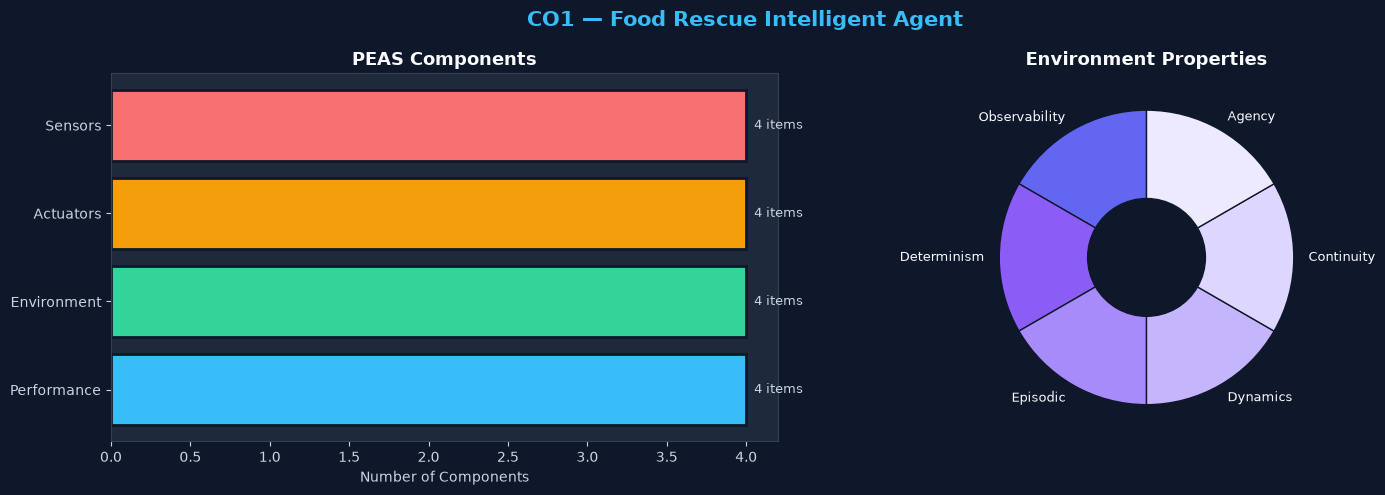

In [3]:
# ─── CO1 Visualisation ────────────────────────────────────────
if PLOT:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    fig.patch.set_facecolor('#0f172a')

    # Left — PEAS bar chart
    ax = axes[0]
    ax.set_facecolor('#1e293b')
    cats   = list(PEAS.keys())
    counts = [len(v) for v in PEAS.values()]
    clrs   = ['#38bdf8', '#34d399', '#f59e0b', '#f87171']
    bars   = ax.barh(cats, counts, color=clrs, edgecolor='#0f172a', linewidth=2)
    ax.set_xlabel('Number of Components', color='#cbd5e1')
    ax.set_title('PEAS Components', color='#f8fafc', fontsize=13, fontweight='bold')
    ax.tick_params(colors='#cbd5e1')
    ax.spines[:].set_color('#334155')
    for bar, c in zip(bars, counts):
        ax.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height()/2,
                f'{c} items', va='center', color='#cbd5e1', fontsize=9)

    # Right — Environment properties donut
    ax2 = axes[1]
    ax2.set_facecolor('#1e293b')
    props = list(ENV_PROPS.keys())
    pie_c = ['#6366f1','#8b5cf6','#a78bfa','#c4b5fd','#ddd6fe','#ede9fe']
    wedges, texts = ax2.pie([1]*len(props), labels=props, colors=pie_c,
                             startangle=90, wedgeprops=dict(width=0.6, edgecolor='#0f172a'))
    for t in texts:
        t.set_color('#f8fafc'); t.set_fontsize(9)
    ax2.set_title('Environment Properties', color='#f8fafc', fontsize=13, fontweight='bold')

    plt.suptitle('CO1 — Food Rescue Intelligent Agent', color='#38bdf8',
                 fontsize=15, fontweight='bold')
    plt.tight_layout()
    plt.show()

---
## 🗂️ Scenario Data

Four scenarios mirror `data/scenarios.json`:

| Scenario | Description |
|---|---|
| **normal** | Sufficient capacity and time |
| **tight** | Limited vehicle/kitchen capacity, critical donation |
| **changed** | Road closed + vehicle unavailable |
| **failure** | Dairy donation but no cold-storage kitchen |

In [4]:
# ════════════════════════════════════════════════════════════════
# Scenario Data (mirrors data/scenarios.json)
# ════════════════════════════════════════════════════════════════
ROADS_COMMON = [
    ['DEPOT','P1',2],['DEPOT','P2',3],['DEPOT','P3',4],['DEPOT','P4',2],['DEPOT','P5',3],
    ['P1','K1',2],['P1','K2',3],['P1','K3',4],
    ['P2','K1',2],['P2','K2',2],['P2','K3',3],
    ['P3','K1',4],['P3','K2',2],['P3','K3',5],
    ['P4','K1',3],['P4','K2',2],['P4','K3',4],
    ['P5','K1',2],['P5','K2',3],['P5','K3',4],
    ['K1','K2',2],['K2','K3',2],['K1','K3',4],
    ['DEPOT','K1',4],['DEPOT','K2',5],['DEPOT','K3',6],
]
KITCHENS_345 = [
    {'id':'K1','needs':['cooked','vegetables','bakery'],         'capacity_kg':20,'cold_storage':False},
    {'id':'K2','needs':['cooked','vegetables','dairy','bakery'], 'capacity_kg':25,'cold_storage':True},
    {'id':'K3','needs':['cooked','vegetables'],                  'capacity_kg':15,'cold_storage':False},
]
VEHICLES_20 = [
    {'id':'V1','capacity_kg':20,'available':True, 'start':'DEPOT'},
    {'id':'V2','capacity_kg':20,'available':True, 'start':'DEPOT'},
]

SCENARIOS = {
  'normal': {
    'description': 'Normal case: sufficient capacity and time.',
    'donations': [
      {'id':'D1','provider':'P1','food_type':'cooked',    'kg':8,'hours_to_expiry':3.0},
      {'id':'D2','provider':'P2','food_type':'vegetables','kg':6,'hours_to_expiry':8.0},
      {'id':'D3','provider':'P3','food_type':'dairy',     'kg':5,'hours_to_expiry':4.0},
      {'id':'D4','provider':'P4','food_type':'cooked',    'kg':7,'hours_to_expiry':1.5},
      {'id':'D5','provider':'P5','food_type':'bakery',    'kg':4,'hours_to_expiry':10.0},
    ],
    'kitchens': KITCHENS_345,
    'vehicles': VEHICLES_20,
    'roads': ROADS_COMMON,
    'closed_roads':[], 'unavailable_vehicles':[],
  },
  'tight': {
    'description': 'Tight case: limited vehicle capacity and a critical donation.',
    'donations': [
      {'id':'D1','provider':'P1','food_type':'cooked',    'kg':12,'hours_to_expiry':1.0},
      {'id':'D2','provider':'P2','food_type':'vegetables','kg':10,'hours_to_expiry':5.0},
      {'id':'D3','provider':'P3','food_type':'dairy',     'kg': 8,'hours_to_expiry':3.0},
      {'id':'D4','provider':'P4','food_type':'cooked',    'kg': 7,'hours_to_expiry':1.5},
      {'id':'D5','provider':'P5','food_type':'bakery',    'kg': 6,'hours_to_expiry':7.0},
    ],
    'kitchens': [
      {'id':'K1','needs':['cooked','vegetables','bakery'],         'capacity_kg':15,'cold_storage':False},
      {'id':'K2','needs':['cooked','vegetables','dairy','bakery'], 'capacity_kg':18,'cold_storage':True},
      {'id':'K3','needs':['cooked','vegetables'],                  'capacity_kg':12,'cold_storage':False},
    ],
    'vehicles': [
      {'id':'V1','capacity_kg':15,'available':True,'start':'DEPOT'},
      {'id':'V2','capacity_kg':15,'available':True,'start':'DEPOT'},
    ],
    'roads': ROADS_COMMON,
    'closed_roads':[], 'unavailable_vehicles':[],
  },
  'changed': {
    'description': 'Changed case: one road closed, one vehicle unavailable.',
    'donations': [
      {'id':'D1','provider':'P1','food_type':'cooked',    'kg':8,'hours_to_expiry':3.0},
      {'id':'D2','provider':'P2','food_type':'vegetables','kg':6,'hours_to_expiry':8.0},
      {'id':'D3','provider':'P3','food_type':'dairy',     'kg':5,'hours_to_expiry':4.0},
      {'id':'D4','provider':'P4','food_type':'cooked',    'kg':7,'hours_to_expiry':1.5},
      {'id':'D5','provider':'P5','food_type':'bakery',    'kg':4,'hours_to_expiry':10.0},
    ],
    'kitchens': KITCHENS_345,
    'vehicles': [
      {'id':'V1','capacity_kg':20,'available':True, 'start':'DEPOT'},
      {'id':'V2','capacity_kg':20,'available':False,'start':'DEPOT'},
    ],
    'roads': ROADS_COMMON,
    'closed_roads':[['P1','K2']], 'unavailable_vehicles':['V2'],
  },
  'failure': {
    'description': 'Failure case: dairy donation but no cold-storage kitchen.',
    'donations': [
      {'id':'D6','provider':'P6','food_type':'dairy','kg':5,'hours_to_expiry':3.0},
    ],
    'kitchens': [
      {'id':'K1','needs':['dairy','cooked'],'capacity_kg':10,'cold_storage':False},
      {'id':'K2','needs':['dairy'],         'capacity_kg':10,'cold_storage':False},
    ],
    'vehicles': [{'id':'V1','capacity_kg':10,'available':True,'start':'DEPOT'}],
    'roads': [
      ['DEPOT','P6',1],['P6','K1',1],['P6','K2',2],['DEPOT','K1',2],['DEPOT','K2',3]
    ],
    'closed_roads':[], 'unavailable_vehicles':[],
  },
}
print(f'✅ {len(SCENARIOS)} scenarios loaded: {list(SCENARIOS.keys())}')

✅ 4 scenarios loaded: ['normal', 'tight', 'changed', 'failure']


---
## 🧠 Section 2 — CO4: Knowledge-Base & Forward-Chaining Inference

**Forward chaining** starts from known facts and fires rules to derive conclusions.

### Rules
| Rule | Logic |
|---|---|
| `urgency` | `hours_to_expiry ≤ 2` → CRITICAL; `≤ 5` → HIGH; else NORMAL |
| `storage_compat` | Dairy requires `cold_storage = True` |
| `food_needed` | `food_type` must be in kitchen's `needs` list |
| `eligibility` | `food_needed` AND `storage_compat` |

In [5]:
# ════════════════════════════════════════════════════════════════
# CO4 — Knowledge-Base Rules
# ════════════════════════════════════════════════════════════════

def urgency(donation):
    h = donation['hours_to_expiry']
    if h <= 2:  return '🔴 CRITICAL'
    if h <= 5:  return '🟡 HIGH'
    return          '🟢 NORMAL'

def is_storage_compatible(donation, kitchen):
    if donation['food_type'] == 'dairy' and not kitchen['cold_storage']:
        return False
    return True

def is_food_needed(donation, kitchen):
    return donation['food_type'] in kitchen['needs']

def is_eligible(donation, kitchen):
    return is_food_needed(donation, kitchen) and is_storage_compatible(donation, kitchen)

def facts_for(donation, kitchens):
    return {
        'donation'         : donation['id'],
        'food_type'        : donation['food_type'],
        'hours_to_expiry'  : donation['hours_to_expiry'],
        'urgency'          : urgency(donation),
        'eligible_kitchens': [k['id'] for k in kitchens if is_eligible(donation, k)],
    }

def evaluate_donations(donations, kitchens):
    """Forward-chaining evaluation with reasoning trace."""
    results, trace = [], []
    for d in donations:
        f = facts_for(d, kitchens)
        trace.append(f"  FACT : {d['id']} is {d['food_type']}, {d['kg']} kg, expires in {d['hours_to_expiry']} h")
        trace.append(f"  RULE urgency     → {d['id']} is {f['urgency']}")
        if f['eligible_kitchens']:
            trace.append(f"  RULE eligibility → {d['id']} can go to {', '.join(f['eligible_kitchens'])}")
        else:
            trace.append(f"  RULE eligibility → {d['id']} ❌  NO compatible kitchen")
        trace.append('')
        results.append({**d, **f})
    return results, trace

print('✅ CO4 Knowledge-Base rules defined.')

✅ CO4 Knowledge-Base rules defined.


In [6]:
# ─── Run CO4 on NORMAL scenario ───────────────────────────────
sc_n = SCENARIOS['normal']
evaluated, trace = evaluate_donations(sc_n['donations'], sc_n['kitchens'])

print('═' * 68)
print(' CO4: KNOWLEDGE-BASE FORWARD-CHAINING TRACE — NORMAL'.center(68))
print('═' * 68)
for line in trace:
    print(line)

# Queries
critical = [d['id'] for d in sc_n['donations'] if urgency(d) == '🔴 CRITICAL']
print('─' * 68)
print(f'  Query 1 — Critical donations    : {critical}')
d3 = next(d for d in sc_n['donations'] if d['id'] == 'D3')
k2 = next(k for k in sc_n['kitchens']  if k['id'] == 'K2')
k1 = next(k for k in sc_n['kitchens']  if k['id'] == 'K1')
print(f'  Query 2 — D3 deliverable to K2 : {is_eligible(d3, k2)} (cold_storage={k2["cold_storage"]})')
print(f'  Query 3 — D3 deliverable to K1 : {is_eligible(d3, k1)} (cold_storage={k1["cold_storage"]})')
print('═' * 68)

════════════════════════════════════════════════════════════════════
         CO4: KNOWLEDGE-BASE FORWARD-CHAINING TRACE — NORMAL        
════════════════════════════════════════════════════════════════════
  FACT : D1 is cooked, 8 kg, expires in 3.0 h
  RULE urgency     → D1 is 🟡 HIGH
  RULE eligibility → D1 can go to K1, K2, K3

  FACT : D2 is vegetables, 6 kg, expires in 8.0 h
  RULE urgency     → D2 is 🟢 NORMAL
  RULE eligibility → D2 can go to K1, K2, K3

  FACT : D3 is dairy, 5 kg, expires in 4.0 h
  RULE urgency     → D3 is 🟡 HIGH
  RULE eligibility → D3 can go to K2

  FACT : D4 is cooked, 7 kg, expires in 1.5 h
  RULE urgency     → D4 is 🔴 CRITICAL
  RULE eligibility → D4 can go to K1, K2, K3

  FACT : D5 is bakery, 4 kg, expires in 10.0 h
  RULE urgency     → D5 is 🟢 NORMAL
  RULE eligibility → D5 can go to K1, K2

────────────────────────────────────────────────────────────────────
  Query 1 — Critical donations    : ['D4']
  Query 2 — D3 deliverable to K2 : True (cold_stora

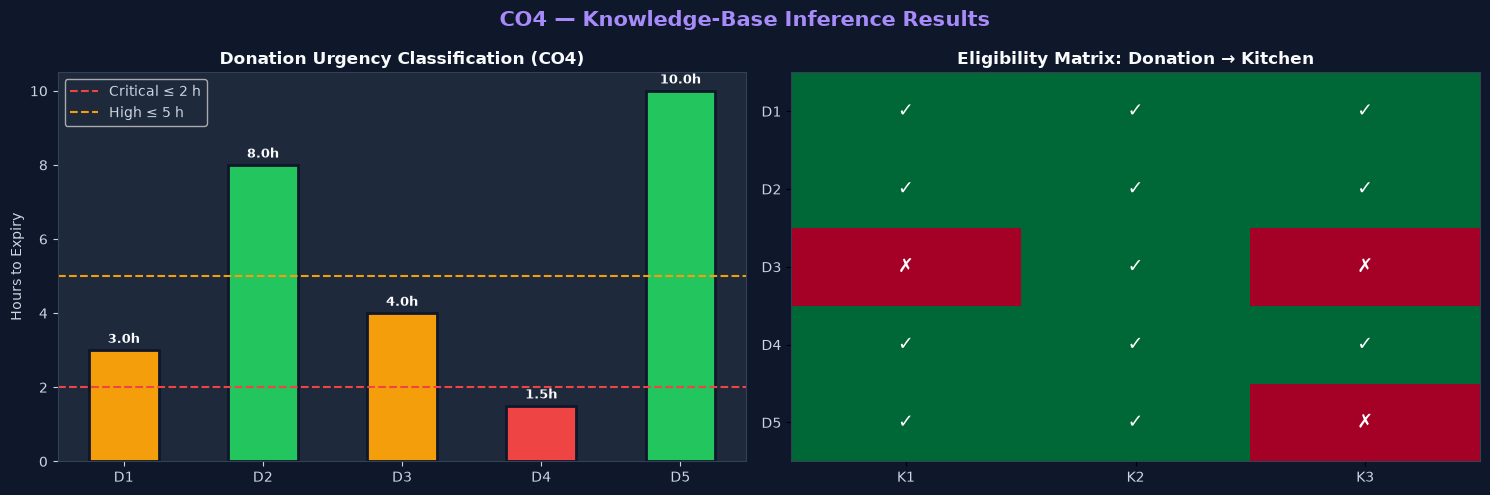

In [7]:
# ─── CO4 Visualisation ────────────────────────────────────────
if PLOT:
    URGENCY_CLR = {'🔴 CRITICAL':'#ef4444', '🟡 HIGH':'#f59e0b', '🟢 NORMAL':'#22c55e'}
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    fig.patch.set_facecolor('#0f172a')

    # Left — Urgency bar
    ax = axes[0]
    ax.set_facecolor('#1e293b')
    ids   = [e['donation'] for e in evaluated]
    hours = [e['hours_to_expiry'] for e in evaluated]
    cols  = [URGENCY_CLR[e['urgency']] for e in evaluated]
    bars  = ax.bar(ids, hours, color=cols, edgecolor='#0f172a', linewidth=2, width=0.5)
    ax.axhline(2, color='#ef4444', linestyle='--', linewidth=1.5, label='Critical ≤ 2 h')
    ax.axhline(5, color='#f59e0b', linestyle='--', linewidth=1.5, label='High ≤ 5 h')
    ax.set_ylabel('Hours to Expiry', color='#cbd5e1')
    ax.set_title('Donation Urgency Classification (CO4)', color='#f8fafc', fontsize=12, fontweight='bold')
    ax.tick_params(colors='#cbd5e1'); ax.spines[:].set_color('#334155')
    ax.legend(facecolor='#1e293b', labelcolor='#cbd5e1')
    for bar, h in zip(bars, hours):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.2,
                f'{h}h', ha='center', color='#f8fafc', fontsize=9, fontweight='bold')

    # Right — Eligibility matrix
    ax2 = axes[1]
    ax2.set_facecolor('#1e293b')
    all_k  = [k['id'] for k in sc_n['kitchens']]
    matrix = np.array([[1 if kid in e['eligible_kitchens'] else 0
                        for kid in all_k] for e in evaluated], dtype=float)
    ax2.imshow(matrix, cmap='RdYlGn', aspect='auto', vmin=0, vmax=1)
    ax2.set_xticks(range(len(all_k)));    ax2.set_xticklabels(all_k, color='#cbd5e1')
    ax2.set_yticks(range(len(evaluated))); ax2.set_yticklabels(ids, color='#cbd5e1')
    ax2.set_title('Eligibility Matrix: Donation → Kitchen', color='#f8fafc', fontsize=12, fontweight='bold')
    for i in range(len(evaluated)):
        for j in range(len(all_k)):
            ax2.text(j, i, '✓' if matrix[i][j] else '✗', ha='center', va='center',
                     color='white', fontsize=14, fontweight='bold')
    ax2.spines[:].set_color('#334155')

    plt.suptitle('CO4 — Knowledge-Base Inference Results', color='#a78bfa', fontsize=15, fontweight='bold')
    plt.tight_layout()
    plt.show()

---
## 🧩 Section 3 — CO3: CSP — Backtracking & Forward Checking

### CSP Formulation
- **Variables** — one per donation: which (vehicle, kitchen) to assign  
- **Domain** — valid (vehicle, kitchen) pairs (capacity & eligibility constraints)  
- **Constraints** — cumulative vehicle & kitchen capacity limits

### Solving Strategies
| Strategy | How It Works |
|---|---|
| **Backtracking** | Try assignments; backtrack on constraint violation |
| **Forward Checking** | After each assignment, prune future domains; fail early |

In [8]:
# ════════════════════════════════════════════════════════════════
# CO3 — CSP Solvers
# ════════════════════════════════════════════════════════════════

def candidates_for(donation, kitchens, vehicles):
    """Build initial domain: valid (vehicle, kitchen) pairs."""
    return [
        (v['id'], k['id'])
        for v in vehicles if v['available'] and donation['kg'] <= v['capacity_kg']
        for k in kitchens if is_eligible(donation, k)
    ]

# ─── Backtracking ─────────────────────────────────────────────
def allocate_backtracking(donations, kitchens, vehicles):
    domains      = {d['id']: candidates_for(d, kitchens, vehicles) for d in donations}
    ordered      = sorted(donations, key=lambda d: (len(domains[d['id']]), d['hours_to_expiry'], -d['kg']))
    v_by_id      = {v['id']: v for v in vehicles}
    k_by_id      = {k['id']: k for k in kitchens}
    used_v       = {v['id']: 0 for v in vehicles}
    used_k       = {k['id']: 0 for k in kitchens}
    assignment, attempts = {}, 0

    def search(idx):
        nonlocal attempts
        if idx == len(ordered): return True
        d, did = ordered[idx], ordered[idx]['id']
        if not domains[did]:
            assignment[did] = None; return search(idx + 1)
        for vid, kid in domains[did]:
            attempts += 1
            if used_v[vid] + d['kg'] > v_by_id[vid]['capacity_kg']: continue
            if used_k[kid] + d['kg'] > k_by_id[kid]['capacity_kg']: continue
            assignment[did] = {'vehicle': vid, 'kitchen': kid}
            used_v[vid] += d['kg']; used_k[kid] += d['kg']
            if search(idx + 1): return True
            used_v[vid] -= d['kg']; used_k[kid] -= d['kg']
            assignment.pop(did, None)
        assignment[did] = None
        if search(idx + 1): return True
        assignment.pop(did, None)
        return False

    search(0)
    return assignment, attempts

# ─── Forward Checking ─────────────────────────────────────────
def allocate_forward_checking(donations, kitchens, vehicles):
    v_by_id = {v['id']: v for v in vehicles}
    k_by_id = {k['id']: k for k in kitchens}
    domains  = {d['id']: candidates_for(d, kitchens, vehicles) for d in donations}
    ordered  = sorted(donations, key=lambda d: (len(domains[d['id']]), d['hours_to_expiry']))
    rem_v    = {v['id']: v['capacity_kg'] for v in vehicles}
    rem_k    = {k['id']: k['capacity_kg'] for k in kitchens}
    assignment, attempts = {}, 0

    def search(idx, cur_dom):
        nonlocal attempts
        if idx == len(ordered): return True
        d, did = ordered[idx], ordered[idx]['id']
        if not cur_dom[did]:
            assignment[did] = None; return search(idx + 1, cur_dom)
        for vid, kid in cur_dom[did]:
            attempts += 1
            if d['kg'] > rem_v[vid] or d['kg'] > rem_k[kid]: continue
            assignment[did] = {'vehicle': vid, 'kitchen': kid}
            rem_v[vid] -= d['kg']; rem_k[kid] -= d['kg']
            nxt = {key: list(val) for key, val in cur_dom.items()}
            for fut in ordered[idx + 1:]:
                fid = fut['id']
                nxt[fid] = [(v, k) for v, k in nxt[fid]
                            if fut['kg'] <= rem_v[v] and fut['kg'] <= rem_k[k]]
            if search(idx + 1, nxt): return True
            rem_v[vid] += d['kg']; rem_k[kid] += d['kg']
            assignment.pop(did, None)
        assignment[did] = None
        if search(idx + 1, cur_dom): return True
        assignment.pop(did, None)
        return False

    search(0, domains)
    return assignment, attempts

print('✅ CSP Backtracking and Forward Checking solvers defined.')

✅ CSP Backtracking and Forward Checking solvers defined.


In [9]:
# ─── Run CSP on all 4 scenarios ───────────────────────────────
csp_stats = {}
for name, sc in SCENARIOS.items():
    veh = [{**v, 'available': v['available'] and v['id'] not in sc.get('unavailable_vehicles', [])}
           for v in sc['vehicles']]
    abt, att_bt = allocate_backtracking(sc['donations'], sc['kitchens'], veh)
    afc, att_fc = allocate_forward_checking(sc['donations'], sc['kitchens'], veh)
    assigned_kg = sum(d['kg'] for d in sc['donations'] if abt.get(d['id']))
    total_kg    = sum(d['kg'] for d in sc['donations'])
    csp_stats[name] = dict(abt=abt, att_bt=att_bt, att_fc=att_fc,
                            assigned_kg=assigned_kg, total_kg=total_kg,
                            assigned_n=sum(1 for d in sc['donations'] if abt.get(d['id'])),
                            total_n=len(sc['donations']))

# Print NORMAL result
r = csp_stats['normal']
print('═' * 68)
print(' CO3: CSP ALLOCATION — NORMAL SCENARIO'.center(68))
print('═' * 68)
print(f'  Backtracking attempts : {r["att_bt"]}')
print(f'  Forward-check attempts: {r["att_fc"]}'
      f'  ({"fewer ✅" if r["att_fc"] < r["att_bt"] else "same"} than backtracking)')
print()
for d in SCENARIOS['normal']['donations']:
    alloc = r['abt'].get(d['id'])
    if alloc:
        print(f"  {d['id']} ({d['kg']:>2} kg, {d['food_type']:>10}) → vehicle {alloc['vehicle']} → kitchen {alloc['kitchen']}")
    else:
        print(f"  {d['id']} ({d['kg']:>2} kg, {d['food_type']:>10}) → ❌ UNASSIGNED")
print(f"\n  Assigned: {r['assigned_n']}/{r['total_n']} donations  ({r['assigned_kg']}/{r['total_kg']} kg)")
print('═' * 68)

════════════════════════════════════════════════════════════════════
                CO3: CSP ALLOCATION — NORMAL SCENARIO               
════════════════════════════════════════════════════════════════════
  Backtracking attempts : 12
  Forward-check attempts: 5  (fewer ✅ than backtracking)

  D1 ( 8 kg,     cooked) → vehicle V2 → kitchen K1
  D2 ( 6 kg, vegetables) → vehicle V2 → kitchen K2
  D3 ( 5 kg,      dairy) → vehicle V1 → kitchen K2
  D4 ( 7 kg,     cooked) → vehicle V1 → kitchen K1
  D5 ( 4 kg,     bakery) → vehicle V1 → kitchen K1

  Assigned: 5/5 donations  (30/30 kg)
════════════════════════════════════════════════════════════════════


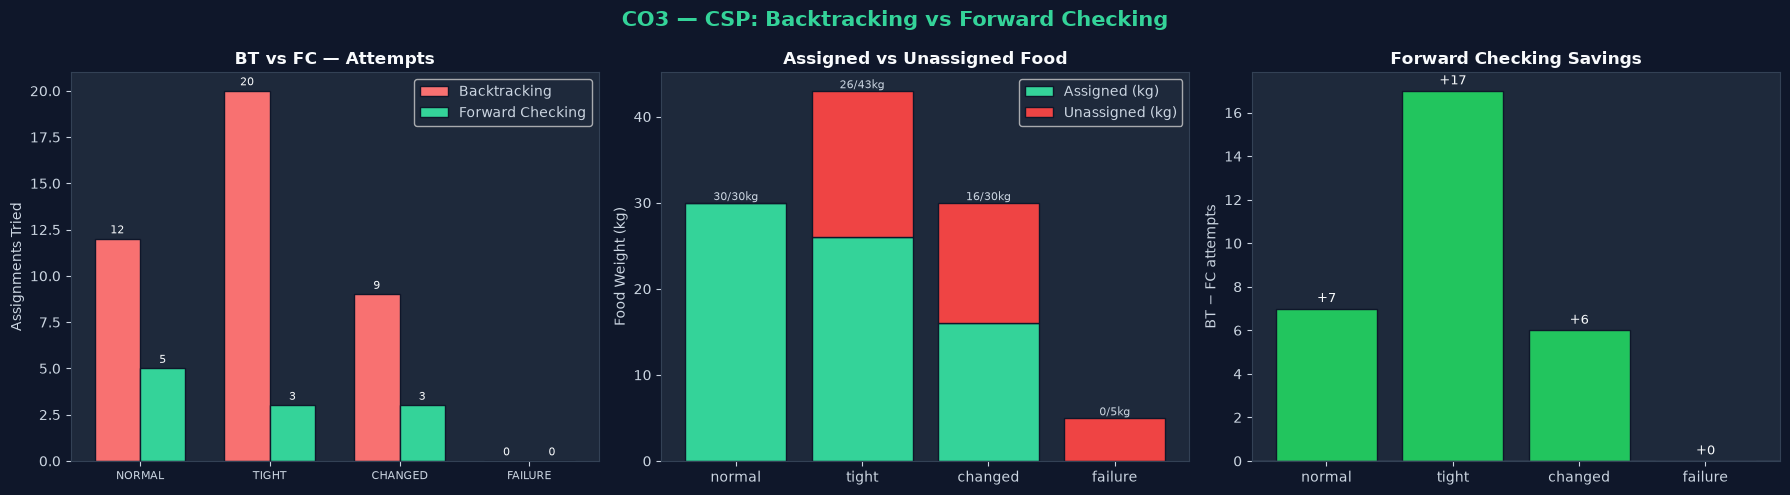

In [10]:
# ─── CO3 Visualisation ────────────────────────────────────────
if PLOT:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.patch.set_facecolor('#0f172a')
    snames = list(csp_stats.keys())
    x = np.arange(len(snames)); w = 0.35

    # Panel 1 — Attempts comparison
    ax = axes[0]; ax.set_facecolor('#1e293b')
    b1 = ax.bar(x-w/2, [csp_stats[s]['att_bt'] for s in snames], w, label='Backtracking',     color='#f87171', edgecolor='#0f172a')
    b2 = ax.bar(x+w/2, [csp_stats[s]['att_fc'] for s in snames], w, label='Forward Checking', color='#34d399', edgecolor='#0f172a')
    ax.set_xticks(x); ax.set_xticklabels([s.upper() for s in snames], color='#cbd5e1', fontsize=8)
    ax.set_ylabel('Assignments Tried', color='#cbd5e1')
    ax.set_title('BT vs FC — Attempts', color='#f8fafc', fontsize=12, fontweight='bold')
    ax.legend(facecolor='#1e293b', labelcolor='#cbd5e1')
    ax.tick_params(colors='#cbd5e1'); ax.spines[:].set_color('#334155')
    for b in [b1, b2]:
        for bar in b:
            ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3,
                    str(int(bar.get_height())), ha='center', color='#f8fafc', fontsize=8)

    # Panel 2 — Rescued vs wasted
    ax2 = axes[1]; ax2.set_facecolor('#1e293b')
    rescued = [csp_stats[s]['assigned_kg'] for s in snames]
    wasted  = [csp_stats[s]['total_kg'] - csp_stats[s]['assigned_kg'] for s in snames]
    ax2.bar(snames, rescued, color='#34d399', label='Assigned (kg)',   edgecolor='#0f172a')
    ax2.bar(snames, wasted,  color='#ef4444', bottom=rescued, label='Unassigned (kg)', edgecolor='#0f172a')
    ax2.set_ylabel('Food Weight (kg)', color='#cbd5e1')
    ax2.set_title('Assigned vs Unassigned Food', color='#f8fafc', fontsize=12, fontweight='bold')
    ax2.legend(facecolor='#1e293b', labelcolor='#cbd5e1')
    ax2.tick_params(colors='#cbd5e1'); ax2.spines[:].set_color('#334155')
    for i, (r, t) in enumerate(zip(rescued, [csp_stats[s]['total_kg'] for s in snames])):
        ax2.text(i, t+0.3, f'{r}/{t}kg', ha='center', color='#cbd5e1', fontsize=8)

    # Panel 3 — FC savings
    ax3 = axes[2]; ax3.set_facecolor('#1e293b')
    savings = [csp_stats[s]['att_bt'] - csp_stats[s]['att_fc'] for s in snames]
    clrs3   = ['#22c55e' if s >= 0 else '#ef4444' for s in savings]
    ax3.bar(snames, savings, color=clrs3, edgecolor='#0f172a')
    ax3.axhline(0, color='#64748b', linewidth=1)
    ax3.set_ylabel('BT − FC attempts', color='#cbd5e1')
    ax3.set_title('Forward Checking Savings', color='#f8fafc', fontsize=12, fontweight='bold')
    ax3.tick_params(colors='#cbd5e1'); ax3.spines[:].set_color('#334155')
    for i, s in enumerate(savings):
        ax3.text(i, s+(0.3 if s >= 0 else -0.6), f'{s:+d}', ha='center', color='#f8fafc', fontsize=9)

    plt.suptitle('CO3 — CSP: Backtracking vs Forward Checking', color='#34d399', fontsize=15, fontweight='bold')
    plt.tight_layout()
    plt.show()

---
## 🗺️ Section 4 — CO2: Search — UCS vs A\*

### Uniform-Cost Search (UCS)
- Expands the node with the **lowest cumulative cost** `g(n)`
- Guaranteed optimal; explores all directions equally

### A\* Search
- Expands lowest `f(n) = g(n) + h(n)`  
- With admissible heuristic, finds optimal path  
- Here `h = 0` (zero heuristic) → equivalent to UCS; any positive admissible `h` prunes more nodes

In [11]:
# ════════════════════════════════════════════════════════════════
# CO2 — Search Algorithms
# ════════════════════════════════════════════════════════════════

def build_graph(roads, closed_roads=None):
    graph  = {}
    closed = {frozenset(e) for e in (closed_roads or [])}
    for a, b, cost in roads:
        if frozenset((a, b)) in closed: continue
        graph.setdefault(a, {})[b] = cost
        graph.setdefault(b, {})[a] = cost
    return graph

def uniform_cost_search(graph, start, goal):
    counter  = itertools.count()
    frontier = [(0, next(counter), start, [start])]
    best     = {start: 0}
    expanded = 0
    while frontier:
        cost, _, node, path = heapq.heappop(frontier)
        if cost != best.get(node): continue
        expanded += 1
        if node == goal:
            return {'path': path, 'cost': cost, 'nodes_expanded': expanded}
        for nb, w in graph.get(node, {}).items():
            nc = cost + w
            if nc < best.get(nb, float('inf')):
                best[nb] = nc
                heapq.heappush(frontier, (nc, next(counter), nb, path + [nb]))
    return {'path': [], 'cost': float('inf'), 'nodes_expanded': expanded}

def astar_search(graph, start, goal, heuristic=None):
    h        = heuristic or (lambda n, g: 0)
    counter  = itertools.count()
    frontier = [(h(start, goal), 0, next(counter), start, [start])]
    best     = {start: 0}
    expanded = 0
    while frontier:
        _, cost, _, node, path = heapq.heappop(frontier)
        if cost != best.get(node): continue
        expanded += 1
        if node == goal:
            return {'path': path, 'cost': cost, 'nodes_expanded': expanded}
        for nb, w in graph.get(node, {}).items():
            nc = cost + w
            if nc < best.get(nb, float('inf')):
                best[nb] = nc
                heapq.heappush(frontier, (nc + h(nb, goal), nc, next(counter), nb, path + [nb]))
    return {'path': [], 'cost': float('inf'), 'nodes_expanded': expanded}

print('✅ UCS and A* search algorithms defined.')

✅ UCS and A* search algorithms defined.


In [12]:
# ─── Search comparison on NORMAL scenario ─────────────────────
graph_n  = build_graph(SCENARIOS['normal']['roads'], SCENARIOS['normal']['closed_roads'])
abt_norm = csp_stats['normal']['abt']

print('═' * 72)
print(' CO2: UCS vs A* — NORMAL SCENARIO'.center(72))
print('═' * 72)
print(f"  {'Donation':<8} {'Route':<22} {'UCS Cost':>9} {'UCS Nodes':>10} {'A* Cost':>9} {'A* Nodes':>9}")
print('  ' + '─' * 66)

search_rows = []
for d in SCENARIOS['normal']['donations']:
    alloc = abt_norm.get(d['id'])
    if not alloc:
        print(f"  {d['id']:<8} UNASSIGNED")
        continue
    src, dst = d['provider'], alloc['kitchen']
    ucs  = uniform_cost_search(graph_n, src, dst)
    ast  = astar_search(graph_n, src, dst)
    route = f'{src}→{dst}'
    print(f"  {d['id']:<8} {route:<22} {ucs['cost']:>9} {ucs['nodes_expanded']:>10} {ast['cost']:>9} {ast['nodes_expanded']:>9}")
    print(f"  {'':8} UCS path : {' → '.join(ucs['path'])}")
    print(f"  {'':8} A*  path : {' → '.join(ast['path'])}")
    print()
    search_rows.append({'id': d['id'], 'route': route,
                        'ucs_cost': ucs['cost'], 'ucs_nodes': ucs['nodes_expanded'],
                        'ast_cost': ast['cost'], 'ast_nodes': ast['nodes_expanded']})
print('═' * 72)

════════════════════════════════════════════════════════════════════════
                    CO2: UCS vs A* — NORMAL SCENARIO                    
════════════════════════════════════════════════════════════════════════
  Donation Route                   UCS Cost  UCS Nodes   A* Cost  A* Nodes
  ──────────────────────────────────────────────────────────────────
  D1       P1→K1                          2          3         2         3
           UCS path : P1 → K1
           A*  path : P1 → K1

  D2       P2→K2                          2          3         2         3
           UCS path : P2 → K2
           A*  path : P2 → K2

  D3       P3→K2                          2          2         2         2
           UCS path : P3 → K2
           A*  path : P3 → K2

  D4       P4→K1                          3          4         3         4
           UCS path : P4 → K1
           A*  path : P4 → K1

  D5       P5→K1                          2          2         2         2
           UCS pat

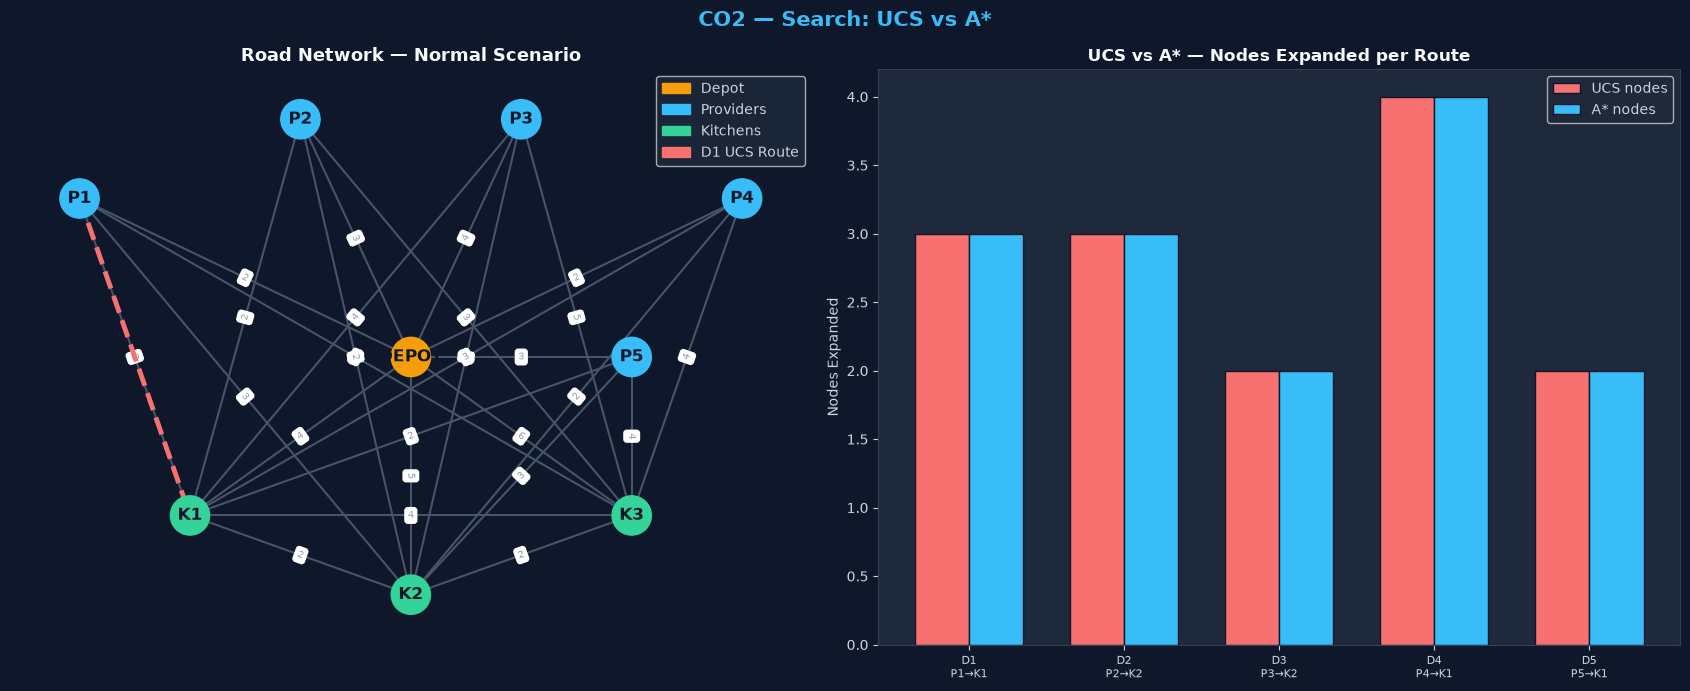

In [13]:
# ─── CO2 Visualisation ────────────────────────────────────────
if PLOT and search_rows:
    fig, axes = plt.subplots(1, 2, figsize=(17, 7))
    fig.patch.set_facecolor('#0f172a')

    # Left — Road network
    ax = axes[0]; ax.set_facecolor('#1e293b')
    G  = nx.Graph()
    for a, b, cost in SCENARIOS['normal']['roads']:
        G.add_edge(a, b, weight=cost)
    pos = {
        'DEPOT': (0, 0),
        'P1':(-3,2),'P2':(-1,3),'P3':(1,3),'P4':(3,2),'P5':(2,0),
        'K1':(-2,-2),'K2':(0,-3),'K3':(2,-2),
    }
    nc = ['#f59e0b' if n=='DEPOT' else '#38bdf8' if n.startswith('P') else '#34d399' for n in G.nodes]
    nx.draw_networkx_nodes(G, pos, node_color=nc, node_size=800, ax=ax)
    nx.draw_networkx_labels(G, pos, font_color='#0f172a', font_weight='bold', ax=ax)
    nx.draw_networkx_edges(G, pos, edge_color='#475569', width=1.5, ax=ax)
    nx.draw_networkx_edge_labels(G, pos, nx.get_edge_attributes(G, 'weight'),
                                  font_color='#94a3b8', font_size=7, ax=ax)

    # Highlight D1 route
    if abt_norm.get('D1'):
        r_ex = uniform_cost_search(graph_n, 'P1', abt_norm['D1']['kitchen'])
        if r_ex['path']:
            nx.draw_networkx_edges(G, pos, edgelist=list(zip(r_ex['path'][:-1], r_ex['path'][1:])),
                                   edge_color='#f87171', width=3.5, style='dashed', ax=ax)
    legend_h = [
        mpatches.Patch(color='#f59e0b', label='Depot'),
        mpatches.Patch(color='#38bdf8', label='Providers'),
        mpatches.Patch(color='#34d399', label='Kitchens'),
        mpatches.Patch(color='#f87171', label='D1 UCS Route'),
    ]
    ax.legend(handles=legend_h, facecolor='#1e293b', labelcolor='#cbd5e1')
    ax.set_title('Road Network — Normal Scenario', color='#f8fafc', fontsize=13, fontweight='bold')
    ax.axis('off')

    # Right — Nodes expanded
    ax2 = axes[1]; ax2.set_facecolor('#1e293b')
    labels = [r['id'] + '\n' + r['route'] for r in search_rows]
    x2 = np.arange(len(search_rows)); w2 = 0.35
    ax2.bar(x2-w2/2, [r['ucs_nodes'] for r in search_rows], w2, label='UCS nodes', color='#f87171', edgecolor='#0f172a')
    ax2.bar(x2+w2/2, [r['ast_nodes'] for r in search_rows], w2, label='A* nodes',  color='#38bdf8', edgecolor='#0f172a')
    ax2.set_xticks(x2); ax2.set_xticklabels(labels, color='#cbd5e1', fontsize=8)
    ax2.set_ylabel('Nodes Expanded', color='#cbd5e1')
    ax2.set_title('UCS vs A* — Nodes Expanded per Route', color='#f8fafc', fontsize=12, fontweight='bold')
    ax2.legend(facecolor='#1e293b', labelcolor='#cbd5e1')
    ax2.tick_params(colors='#cbd5e1'); ax2.spines[:].set_color('#334155')

    plt.suptitle('CO2 — Search: UCS vs A*', color='#38bdf8', fontsize=15, fontweight='bold')
    plt.tight_layout()
    plt.show()

---
## 🚀 Section 5 — Full Multi-Scenario Simulation Dashboard

Runs the **complete CO1→CO4→CO3→CO2 pipeline** across all four scenarios.

In [14]:
# ════════════════════════════════════════════════════════════════
# Full Simulation Pipeline
# ════════════════════════════════════════════════════════════════

def full_simulation(name, scenario, verbose=True):
    don = scenario['donations']
    kit = scenario['kitchens']
    veh = [{**v, 'available': v['available'] and v['id'] not in scenario.get('unavailable_vehicles', [])}
           for v in scenario['vehicles']]
    G   = build_graph(scenario['roads'], scenario.get('closed_roads', []))

    W = 70
    if verbose:
        print('═' * W)
        print(f" SCENARIO: {name.upper()} — {scenario['description']}".center(W))
        print('═' * W)

    _, trace = evaluate_donations(don, kit)
    if verbose:
        print('[CO4] KB TRACE')
        for line in trace: print(line)

    abt, att_bt = allocate_backtracking(don, kit, veh)
    _,   att_fc = allocate_forward_checking(don, kit, veh)
    assigned_kg = sum(d['kg'] for d in don if abt.get(d['id']))
    total_kg    = sum(d['kg'] for d in don)

    if verbose:
        print(f'[CO3] Backtracking: {att_bt} attempts  |  Forward Checking: {att_fc} attempts')
        for d in don:
            alloc = abt.get(d['id'])
            tag   = f"→ {alloc['vehicle']} → {alloc['kitchen']}" if alloc else '❌ UNASSIGNED'
            print(f"      {d['id']} ({d['kg']:>2}kg) {tag}")

    total_cost, total_nodes = 0, 0
    if verbose: print('\n[CO2] UCS / A* ROUTE SEARCH')
    for d in don:
        alloc = abt.get(d['id'])
        if not alloc: continue
        src, dst = d['provider'], alloc['kitchen']
        leg1 = uniform_cost_search(G, 'DEPOT', src)
        leg2 = uniform_cost_search(G, src, dst)
        ast2 = astar_search(G, src, dst)
        if leg1['path'] and leg2['path']:
            full_path = leg1['path'][:-1] + leg2['path']
            full_cost = leg1['cost'] + leg2['cost']
            total_cost  += full_cost
            total_nodes += leg2['nodes_expanded']
            if verbose:
                print(f"      {d['id']}: {' → '.join(full_path)}  cost={full_cost}")
                print(f"           UCS nodes={leg2['nodes_expanded']}  A* nodes={ast2['nodes_expanded']}")
        else:
            if verbose: print(f"      {d['id']}: ⚠️  Route unavailable")

    if verbose:
        print(f'\n[SUMMARY] Assigned: {sum(1 for d in don if abt.get(d["id"]))}/{len(don)} donations'
              f'  |  {assigned_kg}/{total_kg} kg  |  Route cost: {total_cost}')
        print('═' * W)

    return dict(name=name, total_kg=total_kg, assigned_kg=assigned_kg,
                route_cost=total_cost, att_bt=att_bt, att_fc=att_fc,
                assigned_n=sum(1 for d in don if abt.get(d['id'])), total_n=len(don))

sim_results = [full_simulation(n, sc, verbose=True) for n, sc in SCENARIOS.items()]

══════════════════════════════════════════════════════════════════════
     SCENARIO: NORMAL — Normal case: sufficient capacity and time.    
══════════════════════════════════════════════════════════════════════
[CO4] KB TRACE
  FACT : D1 is cooked, 8 kg, expires in 3.0 h
  RULE urgency     → D1 is 🟡 HIGH
  RULE eligibility → D1 can go to K1, K2, K3

  FACT : D2 is vegetables, 6 kg, expires in 8.0 h
  RULE urgency     → D2 is 🟢 NORMAL
  RULE eligibility → D2 can go to K1, K2, K3

  FACT : D3 is dairy, 5 kg, expires in 4.0 h
  RULE urgency     → D3 is 🟡 HIGH
  RULE eligibility → D3 can go to K2

  FACT : D4 is cooked, 7 kg, expires in 1.5 h
  RULE urgency     → D4 is 🔴 CRITICAL
  RULE eligibility → D4 can go to K1, K2, K3

  FACT : D5 is bakery, 4 kg, expires in 10.0 h
  RULE urgency     → D5 is 🟢 NORMAL
  RULE eligibility → D5 can go to K1, K2

[CO3] Backtracking: 12 attempts  |  Forward Checking: 5 attempts
      D1 ( 8kg) → V2 → K1
      D2 ( 6kg) → V2 → K2
      D3 ( 5kg) → V1 → K2

C:\Users\user\AppData\Local\Temp\ipykernel_30784\3179771738.py:55: UserWarning: Glyph 127857 (\N{BENTO BOX}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 127857 (\N{BENTO BOX}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


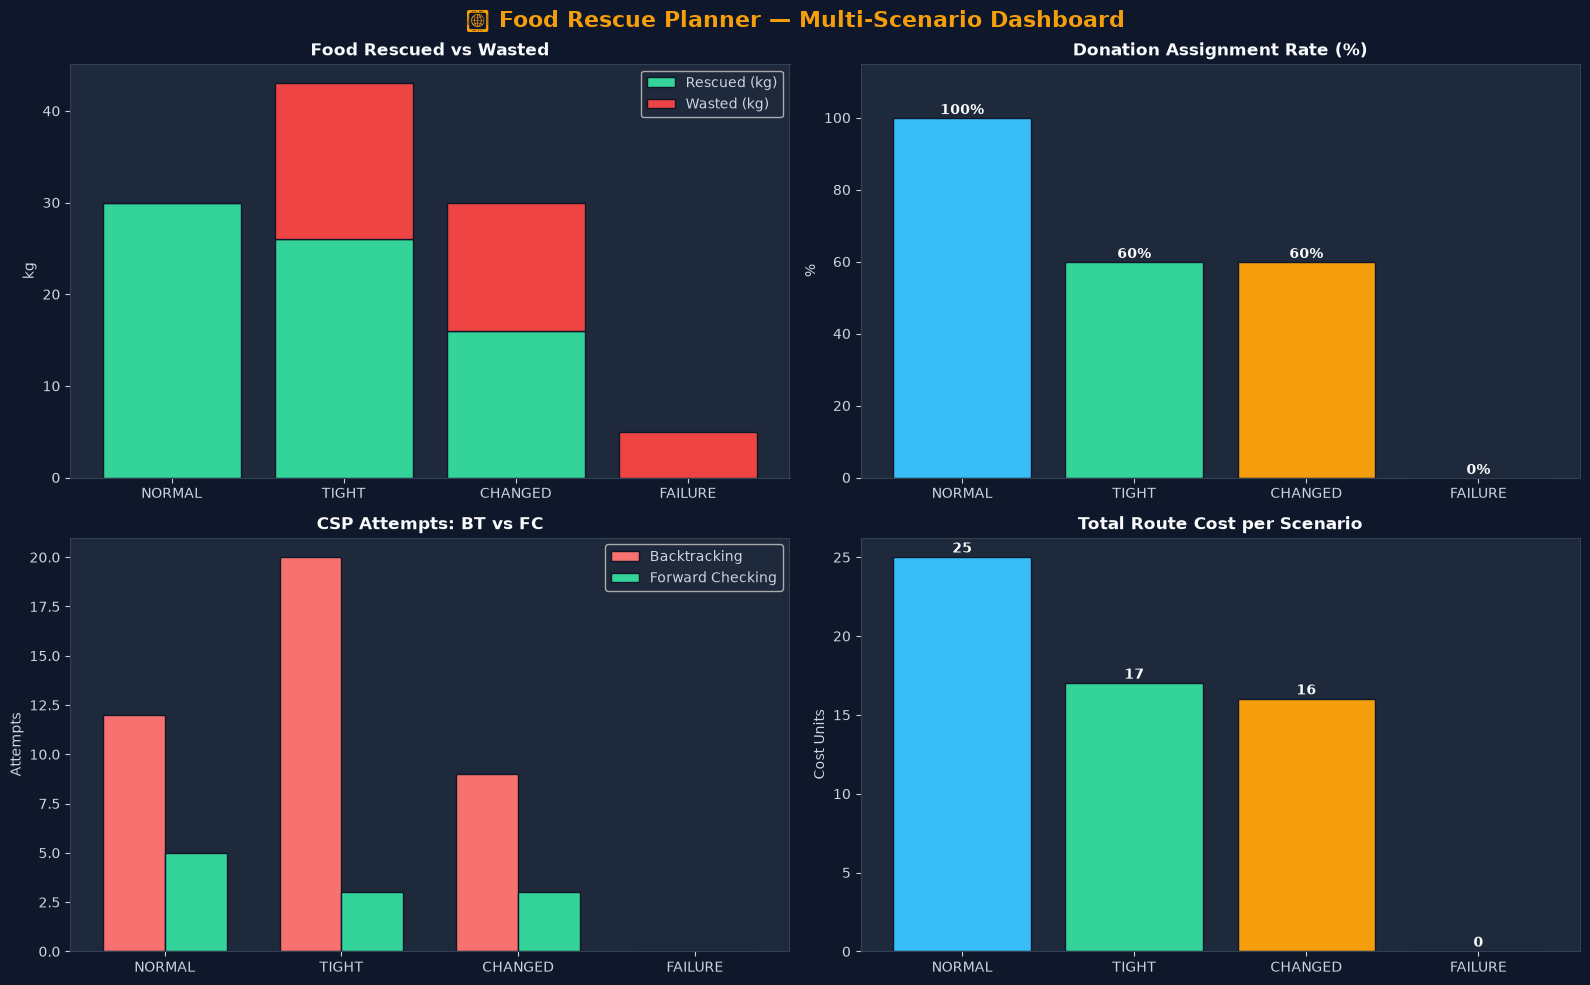

📊 Dashboard rendered.


In [15]:
# ─── Dashboard Visualisation ──────────────────────────────────
if PLOT:
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    fig.patch.set_facecolor('#0f172a')
    plt.suptitle('🍱 Food Rescue Planner — Multi-Scenario Dashboard',
                 color='#f59e0b', fontsize=16, fontweight='bold')
    snames  = [r['name'].upper() for r in sim_results]
    palette = ['#38bdf8','#34d399','#f59e0b','#f87171']

    # Panel 1 — Rescued vs Wasted
    ax = axes[0, 0]; ax.set_facecolor('#1e293b')
    rescued = [r['assigned_kg'] for r in sim_results]
    wasted  = [r['total_kg'] - r['assigned_kg'] for r in sim_results]
    ax.bar(snames, rescued, color='#34d399', label='Rescued (kg)', edgecolor='#0f172a')
    ax.bar(snames, wasted,  color='#ef4444', bottom=rescued, label='Wasted (kg)', edgecolor='#0f172a')
    ax.set_title('Food Rescued vs Wasted', color='#f8fafc', fontweight='bold')
    ax.set_ylabel('kg', color='#cbd5e1')
    ax.legend(facecolor='#1e293b', labelcolor='#cbd5e1')
    ax.tick_params(colors='#cbd5e1'); ax.spines[:].set_color('#334155')

    # Panel 2 — Assignment rate
    ax2 = axes[0, 1]; ax2.set_facecolor('#1e293b')
    rates = [r['assigned_n'] / r['total_n'] * 100 for r in sim_results]
    bars  = ax2.bar(snames, rates, color=palette, edgecolor='#0f172a')
    ax2.set_ylim(0, 115)
    ax2.set_title('Donation Assignment Rate (%)', color='#f8fafc', fontweight='bold')
    ax2.set_ylabel('%', color='#cbd5e1')
    ax2.tick_params(colors='#cbd5e1'); ax2.spines[:].set_color('#334155')
    for bar, r in zip(bars, rates):
        ax2.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1, f'{r:.0f}%',
                 ha='center', color='#f8fafc', fontweight='bold')

    # Panel 3 — CSP attempts
    ax3 = axes[1, 0]; ax3.set_facecolor('#1e293b')
    x3 = np.arange(len(snames)); w3 = 0.35
    ax3.bar(x3-w3/2, [r['att_bt'] for r in sim_results], w3, label='Backtracking',     color='#f87171', edgecolor='#0f172a')
    ax3.bar(x3+w3/2, [r['att_fc'] for r in sim_results], w3, label='Forward Checking', color='#34d399', edgecolor='#0f172a')
    ax3.set_xticks(x3); ax3.set_xticklabels(snames, color='#cbd5e1')
    ax3.set_title('CSP Attempts: BT vs FC', color='#f8fafc', fontweight='bold')
    ax3.set_ylabel('Attempts', color='#cbd5e1')
    ax3.legend(facecolor='#1e293b', labelcolor='#cbd5e1')
    ax3.tick_params(colors='#cbd5e1'); ax3.spines[:].set_color('#334155')

    # Panel 4 — Route costs
    ax4 = axes[1, 1]; ax4.set_facecolor('#1e293b')
    costs = [r['route_cost'] for r in sim_results]
    bars4 = ax4.bar(snames, costs, color=palette, edgecolor='#0f172a')
    ax4.set_title('Total Route Cost per Scenario', color='#f8fafc', fontweight='bold')
    ax4.set_ylabel('Cost Units', color='#cbd5e1')
    ax4.tick_params(colors='#cbd5e1'); ax4.spines[:].set_color('#334155')
    for bar, c in zip(bars4, costs):
        ax4.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3, str(c),
                 ha='center', color='#f8fafc', fontweight='bold')

    plt.tight_layout()
    plt.show()
    print('📊 Dashboard rendered.')

---
## 📊 Section 6 — Summary Table & Conclusions

In [16]:
print('═' * 82)
print(' SIMULATION SUMMARY TABLE'.center(82))
print('═' * 82)
print(f"  {'Scenario':<10} {'Total(kg)':>10} {'Rescued(kg)':>12} {'Rate%':>7}"
      f" {'RouteCost':>10} {'BT_try':>7} {'FC_try':>7} {'FC_saves':>9}")
print('  ' + '─' * 78)
for r in sim_results:
    rate = r['assigned_kg'] / r['total_kg'] * 100 if r['total_kg'] else 0
    save = r['att_bt'] - r['att_fc']
    print(f"  {r['name'].upper():<10} {r['total_kg']:>10} {r['assigned_kg']:>12}"
          f" {rate:>6.0f}% {r['route_cost']:>10} {r['att_bt']:>7} {r['att_fc']:>7} {save:>+9}")
print('═' * 82)
print()
print('  Observations')
print('  ─' * 40)
print('  • NORMAL  : All donations assigned — full food rescue achieved.')
print('  • TIGHT   : Capacity constraints leave some donations unassigned.')
print('  • CHANGED : Road closure + vehicle loss reduces routing options.')
print('  • FAILURE : Dairy donation unassigned — no cold-storage kitchen.')
print()
print('  Algorithmic Takeaways')
print('  ─' * 40)
print('  • Forward Checking prunes domains early → fewer CSP attempts than pure BT.')
print('  • UCS and A* (h=0) find identical optimal paths.')
print('  • A richer heuristic (e.g., geographic distance) would prune A* further.')
print('  • KB urgency rules correctly prioritise CRITICAL (≤ 2 h) donations first.')
print('═' * 82)

══════════════════════════════════════════════════════════════════════════════════
                             SIMULATION SUMMARY TABLE                             
══════════════════════════════════════════════════════════════════════════════════
  Scenario    Total(kg)  Rescued(kg)   Rate%  RouteCost  BT_try  FC_try  FC_saves
  ──────────────────────────────────────────────────────────────────────────────
  NORMAL             30           30    100%         25      12       5        +7
  TIGHT              43           26     60%         17      20       3       +17
  CHANGED            30           16     53%         16       9       3        +6
  FAILURE             5            0      0%          0       0       0        +0
══════════════════════════════════════════════════════════════════════════════════

  Observations
  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─
  • NORMAL  : All donations assigned — f

---
## 🔬 Section 7 — Interactive: Try Your Own Scenario

Edit the data below and **re-run this cell** to simulate your own custom case!

══════════════════════════════════════════════════════════════════════
         SCENARIO: CUSTOM — Custom scenario — edit and re-run!        
══════════════════════════════════════════════════════════════════════
[CO4] KB TRACE
  FACT : DA is cooked, 10 kg, expires in 1.5 h
  RULE urgency     → DA is 🔴 CRITICAL
  RULE eligibility → DA can go to K1, K2

  FACT : DB is dairy, 4 kg, expires in 6.0 h
  RULE urgency     → DB is 🟢 NORMAL
  RULE eligibility → DB can go to K2

  FACT : DC is vegetables, 7 kg, expires in 3.0 h
  RULE urgency     → DC is 🟡 HIGH
  RULE eligibility → DC can go to K1

[CO3] Backtracking: 4 attempts  |  Forward Checking: 2 attempts
      DA (10kg) ❌ UNASSIGNED
      DB ( 4kg) → V1 → K2
      DC ( 7kg) → V1 → K1

[CO2] UCS / A* ROUTE SEARCH
      DB: DEPOT → P3 → K2  cost=6
           UCS nodes=2  A* nodes=2
      DC: DEPOT → P5 → K1  cost=6
           UCS nodes=3  A* nodes=3

[SUMMARY] Assigned: 2/3 donations  |  11/21 kg  |  Route cost: 12
═════════════════════════

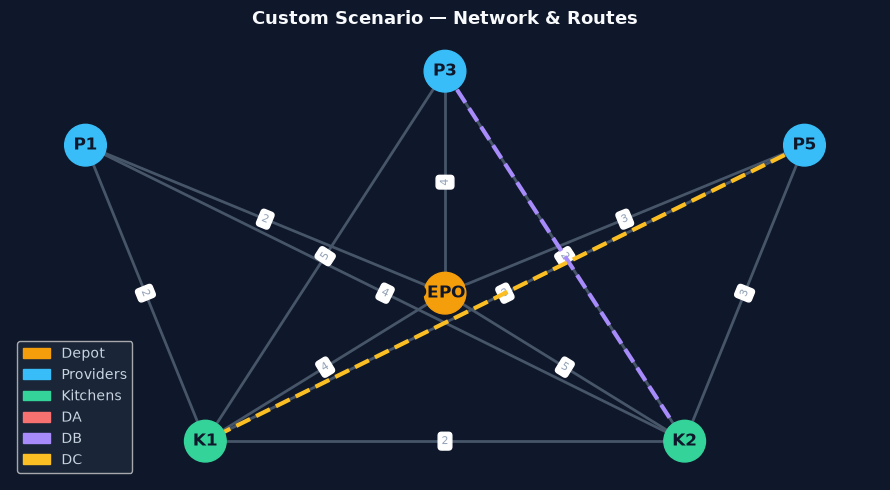

In [17]:
# ═══════════════════════════════════════════════════════════════
# 🎮  Modify these values and run the cell!
# ═══════════════════════════════════════════════════════════════

MY_DONATIONS = [
    {'id':'DA', 'provider':'P1', 'food_type':'cooked',     'kg':10, 'hours_to_expiry':1.5},
    {'id':'DB', 'provider':'P3', 'food_type':'dairy',      'kg': 4, 'hours_to_expiry':6.0},
    {'id':'DC', 'provider':'P5', 'food_type':'vegetables', 'kg': 7, 'hours_to_expiry':3.0},
]

MY_KITCHENS = [
    {'id':'K1', 'needs':['cooked','vegetables'], 'capacity_kg':18, 'cold_storage':False},
    {'id':'K2', 'needs':['dairy','cooked'],      'capacity_kg':12, 'cold_storage':True},
]

MY_VEHICLES = [
    {'id':'V1', 'capacity_kg':15, 'available':True,  'start':'DEPOT'},
    {'id':'V2', 'capacity_kg':10, 'available':False, 'start':'DEPOT'},
]

MY_ROADS = [
    ['DEPOT','P1',2],['DEPOT','P3',4],['DEPOT','P5',3],
    ['P1','K1',2],['P1','K2',4],
    ['P3','K1',5],['P3','K2',2],
    ['P5','K1',3],['P5','K2',3],
    ['DEPOT','K1',4],['DEPOT','K2',5],['K1','K2',2],
]

MY_SCENARIO = {
    'description': 'Custom scenario — edit and re-run!',
    'donations': MY_DONATIONS, 'kitchens': MY_KITCHENS,
    'vehicles': MY_VEHICLES,   'roads': MY_ROADS,
    'closed_roads': [], 'unavailable_vehicles': [],
}

custom_result = full_simulation('custom', MY_SCENARIO, verbose=True)

if PLOT:
    cg = build_graph(MY_ROADS)
    cbt, _ = allocate_backtracking(MY_DONATIONS, MY_KITCHENS, MY_VEHICLES)
    fig, ax = plt.subplots(figsize=(9, 5))
    fig.patch.set_facecolor('#0f172a'); ax.set_facecolor('#1e293b')
    ax.set_title('Custom Scenario — Network & Routes', color='#f8fafc', fontsize=13, fontweight='bold')
    G2 = nx.Graph()
    for a, b, c in MY_ROADS: G2.add_edge(a, b, weight=c)
    pos2 = {'DEPOT':(0,0),'P1':(-3,2),'P3':(0,3),'P5':(3,2),'K1':(-2,-2),'K2':(2,-2)}
    nc2  = ['#f59e0b' if n=='DEPOT' else '#38bdf8' if n.startswith('P') else '#34d399' for n in G2.nodes]
    nx.draw_networkx_nodes(G2, pos2, node_color=nc2, node_size=900, ax=ax)
    nx.draw_networkx_labels(G2, pos2, font_color='#0f172a', font_weight='bold', ax=ax)
    nx.draw_networkx_edges(G2, pos2, edge_color='#475569', width=2, ax=ax)
    nx.draw_networkx_edge_labels(G2, pos2, nx.get_edge_attributes(G2, 'weight'), font_color='#94a3b8', font_size=8, ax=ax)
    route_clrs = ['#f87171','#a78bfa','#fbbf24']
    for i, d in enumerate(MY_DONATIONS):
        alloc = cbt.get(d['id'])
        if not alloc: continue
        r = uniform_cost_search(cg, d['provider'], alloc['kitchen'])
        if r['path']:
            nx.draw_networkx_edges(G2, pos2, edgelist=list(zip(r['path'][:-1], r['path'][1:])),
                                   edge_color=route_clrs[i % len(route_clrs)], width=3, style='dashed', ax=ax)
    legend_h = [
        mpatches.Patch(color='#f59e0b', label='Depot'),
        mpatches.Patch(color='#38bdf8', label='Providers'),
        mpatches.Patch(color='#34d399', label='Kitchens'),
        mpatches.Patch(color='#f87171', label='DA'), mpatches.Patch(color='#a78bfa', label='DB'),
        mpatches.Patch(color='#fbbf24', label='DC'),
    ]
    ax.legend(handles=legend_h, facecolor='#1e293b', labelcolor='#cbd5e1')
    ax.axis('off'); plt.tight_layout(); plt.show()

---
## 📝 Conclusion

| CO | Technique | Takeaway |
|---|---|---|
| CO1 | Intelligent Agent & PEAS | Characterised the agent's perceive-act loop |
| CO4 | Forward-Chaining KB | Urgency, storage compatibility & eligibility derived |
| CO3 | Backtracking + Forward Checking CSP | FC reduces search attempts by early domain pruning |
| CO2 | UCS & A* Search | Optimal routes found; A* ready for richer heuristics |

### Limitations
- Routes planned **independently** — no shared multi-stop vehicle tour
- No real-time traffic or delivery-time feasibility check
- A* uses **zero heuristic** — a geographic heuristic would prune more nodes

### Future Directions
- Vehicle Routing Problem (VRP) with shared multi-stop tours
- Real map data with Haversine heuristic for A*
- Genetic Algorithm / Simulated Annealing for large-scale optimisation

---
*CST401 Artificial Intelligence — KTU 2019 Scheme*  
*Team: Addwin Alanolikkal · Abel J Kolapran · Abhay Achuthan R · Abhijith P S · Abhinav C M · Abhijith C S*